In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import fmatoolbox as fma
import isautilities as isau
import xarray as xr
import powerlaw
import warnings
from scipy.optimize import OptimizeWarning

import pathlib
froot = pathlib.Path().cwd().parent.parent.parent / 'Results'
fig_root = froot / 'Figures' / 'UnitEntrainment'
fres = froot / 'Data' / 'criticalExponents.pkl'
batch_file = '/mnt/hubel-data-103/Pietro/InfraSlowNRPaper/Data/IS_intervals.batch'
results = {}
do_save = False

In [2]:
def _powerlaw_fit(data, xmin=None, xmax=None, drop_unique=False, verbose=False):
    """Fit a discrete power law via Clauset et al. 2009 (MLE).
    returns dict with: tau, sigma, xmin, xmax, R_vs_exp, p_vs_exp, n_tail_proportion, ks_stat, r2 (all NaN on failure)"""
    data = np.round(data).astype(int)
    data = data[data >= 1]
    data_unique, counts = np.unique(data, return_counts=True)
    verbose and print(len(data), "avalanches for power-law fit", len(data_unique), "unique values")
    result = {key: np.nan for key in ('tau','sigma','xmin','xmax','r','p','tail_prop','ks','r2','pdf')}

    # validate input
    if len(data_unique) < 2 or len(data) < 20:
        verbose and print("DATA TOO SMALL OR NOT ENOUGH UNIQUE VALUES FOR POWER-LAW FIT")
        return result
    most_common_freq = np.max(counts) / len(data)
    if most_common_freq > 0.90:
        verbose and print("MOST COMMON VALUE TOO PREVALENT FOR POWER-LAW FIT")
        return result
    if drop_unique:
        data = data[np.isin(data, data_unique[counts > 1])] # drop unique data points

    # empirical PDF of the data (log-binned by default — standard for power-law tails)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        try:
            bin_edges, probability = powerlaw.pdf(data, linear_bins=False)
            center = np.sqrt(bin_edges[:-1] * bin_edges[1:]) # bin center: geometric mean of edges
            result['pdf'] = np.stack((center,probability), axis=1)
        except Exception:
            pass

    if xmax is not None:
        xmax = int(np.percentile(data,xmax)) # apply percentile

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        warnings.simplefilter("ignore", RuntimeWarning)
        warnings.simplefilter("ignore", OptimizeWarning)

        try:
            fit = powerlaw.Fit(data, xmin=xmin, xmax=xmax, discrete=True, verbose=False)
        except Exception:
            return result
        if np.isnan(fit.power_law.alpha):
            return result

        result['tau'] = fit.power_law.alpha
        result['sigma'] = fit.power_law.sigma
        result['xmin'] = fit.xmin
        result['xmax'] = fit.xmax if fit.xmax is not None else np.max(data_unique[-1])
        result['tail_prop'] = fit.n_tail / len(data)

        # compare power law against exponential
        result['r'], result['p'] = fit.distribution_compare('power_law', 'exponential', normalized_ratio=True)

        tail = data[(data >= result['xmin']) & (data <= result['xmax'])]
        theoretical = fit.power_law.cdf(np.sort(tail))
        empirical   = np.arange(1,len(tail)+1) / len(tail)
        result['ks'] = float(np.max(np.abs(empirical - theoretical)))

        # R² en log-log sur la queue fittée
        #x_ccdf, y_ccdf = _ccdf(tail)
        #log_x = np.log(x_ccdf)
        #log_y = np.log(y_ccdf + 1e-12)
        #valid = np.isfinite(log_x) & np.isfinite(log_y)
        #if valid.sum() > 2:
        #    y_pred = np.polyval(np.polyfit(log_x[valid], log_y[valid], 1), log_x[valid])
        #    ss_res = np.sum((log_y[valid] - y_pred)**2)
        #    ss_tot = np.sum((log_y[valid] - log_y[valid].mean())**2)
        #    result['r2'] = 1 - ss_res / ss_tot if ss_tot > 0 else np.nan

    return result

def _gamma_from_scaling(sizes: np.ndarray, durations: np.ndarray) -> float:
    """estimate gamma via OLS regression of log <S|D> on log D"""
    sizes     = np.asarray(sizes,     dtype=float)
    durations = np.asarray(durations, dtype=float)
    valid = (sizes >= 1) & (durations >= 1)
    S, D  = sizes[valid], durations[valid]

    unique_D = np.unique(D)
    if len(unique_D) < 4:
        return np.nan

    mean_S = np.array([S[D == d].mean() for d in unique_D])
    log_D  = np.log(unique_D)
    log_S  = np.log(mean_S)

    keep = np.isfinite(log_D) & np.isfinite(log_S)
    if keep.sum() < 4:
        return np.nan

    gamma, _ = np.polyfit(log_D[keep], log_S[keep], 1)
    return float(gamma)

def plotPowerLaw(pdf, fit, ax, name=None, label=None, **kwargs):
    fma.plotting.plotXY(pdf, label=label, ax=ax, **kwargs)
    ax.axvline(fit.sel(val='xmin'), ls='--', lw=1, **kwargs)
    ax.axvline(fit.sel(val='xmax'), ls='--', lw=1, **kwargs)
    ax.set(xscale='log', yscale='log')
    if name is not None:
        ax.set(xlabel=name, ylabel=f'p({name})')
    ax.set_xticks((1,10,100))
    return

def _plot_ccdf(self, ax: plt.Axes, which: str = "size"):
    """Log-log CCDF + power-law fit for sizes or durations."""
    is_size = (which == "size")
    for res in self.results:
        raw  = res.sizes     if is_size else res.durations
        tau  = res.tau_size  if is_size else res.tau_dur
        xmin = res.xmin_size if is_size else res.xmin_dur
        xmax = res.xmax_size if is_size else res.xmax_dur

        raw = raw[np.isfinite(raw) & (raw >= 1)]
        if len(raw) < 5:
            continue

        x_ccdf, y_ccdf = _ccdf(raw)
        ax.plot(x_ccdf, y_ccdf, ".", color=res.color,
                alpha=0.4, markersize=3, rasterized=True)

        # ── power-law line in the fitted range ──────────────────────
        if np.isfinite(tau) and np.isfinite(xmin):
            xs  = np.logspace(np.log10(xmin), np.log10(xmax), 200)
            # normalise so that the line passes through the CCDF at xmin
            idx   = np.searchsorted(x_ccdf, xmin)
            y0    = y_ccdf[min(idx, len(y_ccdf) - 1)]
            slope = -(tau - 1)
            ys    = y0 * (xs / xmin) ** slope
            R_val = res.R_size if is_size else res.R_dur
            p_val = res.p_size if is_size else res.p_dur
            ks_val = res.ks_size  if is_size else res.ks_dur
            r2_val = res.r2_size  if is_size else res.r2_dur

            label = (f"{res.label}  τ={tau:.2f}±{(res.sigma_size if is_size else res.sigma_dur):.2f}"
                     f"\n[xmin={xmin:.0f}, xmax={xmax:.0f}, xmin/xmax={xmin/xmax:.2f}, n_tail={res.ntail_size:.1%}]"
                     f"\n[R={R_val:.2f}, p_vs_exp={p_val:.3f}, KS={ks_val:.3f}, R²={r2_val:.3f}]")
            ax.axvline(xmin, color=res.color, linewidth=0.8, linestyle=':', alpha=0.7)
            ax.axvline(xmax, color=res.color, linewidth=0.8, linestyle='--', alpha=0.5)
            ax.plot(xs, ys, "-", color=res.color, linewidth=2, label=label)

In [3]:
def _critExp(session,regs=None,when='sleep.*#0',states=['slownr',[['sws','/slownr']]],bin=0.05,bin_mode='fixed',xmin=None,xmax=None,verbose=False):

    R = fma.regions.regions(session, epochs=when, states=['sws','rem'], events='InfraSlowRhythm/infraslowaval')
    regs = R.ids if regs is None else np.array(regs)[np.isin(regs,R.ids)]

    # handle special state
    # tried assigning each ripple to a condition, but not enough avalanches for coupled
    if states == 'rip_coupl':
        events, is_coupl = isau.loadHpcPfcEvents(session, coupl=True)
        window = 5
        peri_ripple = events['ripples'][:,None] + [[-window,window]]
        state_intervals = [peri_ripple[is_coupl['ripples']]]
        state_intervals.append(fma.intervals.subtractIntervals(peri_ripple[~is_coupl['ripples']], state_intervals[0]))
        states = ['rip_coupl','rip_ncoupl']
        threshold = 30
    else:
        state_intervals = [R.eventIntervals(s) for s in states]
        states = [s if isinstance(s,str) else s[0][0]+s[0][1] for s in states]
        threshold = 30

    # fixed bin: precompute avalanches
    if bin_mode != 'isi':
        sizes, intervals, _ = R.avalanches(regs=regs, thresh=threshold, bin_mode=bin_mode, window=bin)
        bin_size = [bin] * len(regs)

    n_aval = np.full((len(regs),len(states)), np.nan)
    fit = np.full((len(regs),len(states),2,8), np.nan) # 4th dim is: sigma, xmin, xmax, R, p, tail_prop, ks, r2
    exponents = np.full((len(regs),len(states),5), np.nan) # 3rd dim is: tau_s, tau_d, gamma_th, gamma_emp, dcc
    pdf = {}
    for j, state in enumerate(states):
        pdf[state] = {}
        # isi case: recompute avalanches per state
        if bin_mode == 'isi':
            sizes, intervals, _, bin_size = R.avalanches(regs=regs, when=state_intervals[j], thresh=threshold, bin_mode=bin_mode, window=bin)

        for i, r in enumerate(regs):
            _, valid = fma.intervals.restrict(intervals[r][:,0], state_intervals[j], s_ind=True)
            sizes_this = sizes[r][valid]
            durations = np.round(np.diff(intervals[r][valid]).ravel() / bin_size[i])
            n_aval[i,j] = len(sizes_this)

            # sizes
            size_fit = _powerlaw_fit(sizes_this, xmin=xmin, xmax=xmax, verbose=verbose)
            fit[i,j,0] = (size_fit['sigma'],size_fit['xmin'],size_fit['xmax'],size_fit['r'],size_fit['p'],size_fit['tail_prop'],size_fit['ks'],size_fit['r2'])
            exponents[i,j,0] = size_fit['tau']

            # durations
            dur_fit = _powerlaw_fit(durations, xmin=xmin, xmax=xmax, verbose=verbose)
            fit[i,j,1] = (dur_fit['sigma'],dur_fit['xmin'],dur_fit['xmax'],dur_fit['r'],dur_fit['p'],dur_fit['tail_prop'],dur_fit['ks'],dur_fit['r2'])
            exponents[i,j,1] = dur_fit['tau']
            pdf[state][r] = {'size':size_fit['pdf'], 'dur':dur_fit['pdf']}

            # DCC
            exponents[i,j,2] = (dur_fit['tau'] - 1) / (size_fit['tau'] - 1) # theoretical gamma from tau exponents
            valid = (sizes_this >= size_fit['xmin']) & (sizes_this <= size_fit['xmax']) & (durations >= dur_fit['xmin']) & (durations <= dur_fit['xmax'])
            exponents[i,j,3] = _gamma_from_scaling(sizes_this[valid], durations[valid]) # gamma from <S> ~ D^gamma scaling relation
            exponents[i,j,4] = abs(exponents[i,j,2] - exponents[i,j,3]) # DCC

    fit = xr.DataArray(fit,dims=('reg','state','q','val'),coords={'reg': regs, 'state': states, 'q': ['S','D'],
                                                                  'val': ['sigma','xmin','xmax','R','p','tail_prop','ks','r2'], 'rat': int(R.rat), 'base':R.basename})
    exponents = xr.DataArray(exponents,dims=('reg','state','val'),coords={'reg': regs, 'state': states, 'val': ['tau_s','tau_d','gamma_th','gamma_sc','DCC'],
                                                                          'rat': int(R.rat), 'base':R.basename})
    n_aval = xr.DataArray(n_aval,dims=('reg','state'), coords={'reg': regs, 'state': states, 'rat': int(R.rat)})

    return fit, exponents, pdf, n_aval

In [7]:
# test on one session
session = fma.data.readBatchFile(batch_file)[0][15]
print(session)
fit, exponents, pdf, n_aval = _critExp(session, states='rip_coupl', bin_mode='isi', bin=1)

/mnt/hubel-data-139/karadoc/Rat004_20240227/Rat004_20240227.xml


ISA vs nISA

In [4]:
regs = ['nr','hpc','pfc']
fit, exponents, pdf, n_aval = fma.data.runBatch(batch_file, _critExp, kwargs={'regs':regs, 'bin_mode':'isi', 'bin':1, 'xmax':99.5}, parallel=True)
fit_cat = xr.concat([f for f in fit if f is not None], dim='base', join='outer')
exponents_cat = xr.concat([f for f in exponents if f is not None], dim='base', join='outer')
results['fit_ISA'] = fit_cat; results['exp_ISA'] = exponents_cat; results['pdf_ISA'] = pdf


Starting Batch, 2026-11-03 17:35:04.349790 

Error in session /mnt/hubel-data-139/karadoc/Rat004_20240303/Rat004_20240303.xml (17)
index 0 is out of bounds for axis 0 with size 0
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230819/Rat002_20230819.xml (38)
index 0 is out of bounds for axis 0 with size 0
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230821/Rat002_20230821.xml (40)
index 0

/tmp/ipykernel_1730532/1248330015.py:3: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  fit_cat = xr.concat([f for f in fit if f is not None], dim='base', join='outer')
/tmp/ipykernel_1730532/1248330015.py:4: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  exponents_cat = xr.concat([f for f in exponents if f is not N

23


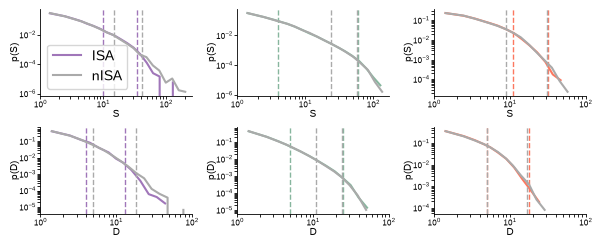

In [48]:
# FIND EXAMPLE WITH BEST range diff: 2? 7? 18? 22?
fig, ax = fma.plotting.figure(n=(2,len(fit_cat.reg)),size=(15,6))
session += 1
print(session)
for i, s in enumerate(pdf[session]):
    for j, r in enumerate(pdf[session][s]):
        color = isau.paperColors(r if i == 0 else 'shuffle')
        plotPowerLaw(pdf[session][s][r]['dur'], fit_cat.sel(reg=r,state=s,q='D')[session], name='D', color=color, ax=ax[1,j])
        plotPowerLaw(pdf[session][s][r]['size'], fit_cat.sel(reg=r,state=s,q='S')[session], name='S', color=color, ax=ax[0,j], label='ISA' if i == 0 else 'nISA')
ax[0,0].legend();
#fma.plotting.saveFigure(fig,'/mnt/hubel-data-103/Pietro/power_law_ex','svg')

0.001 0.442 0.074 

/home/pietro/uvEnvs/fmat/lib/python3.14/site-packages/hierarch/stats.py:536: UserWarning: No levels to bootstrap. Setting bootstraps to zero.
  warn("No levels to bootstrap. Setting bootstraps to zero.")
/home/pietro/uvEnvs/fmat/lib/python3.14/site-packages/hierarch/stats.py:536: UserWarning: No levels to bootstrap. Setting bootstraps to zero.
  warn("No levels to bootstrap. Setting bootstraps to zero.")
/home/pietro/uvEnvs/fmat/lib/python3.14/site-packages/hierarch/stats.py:536: UserWarning: No levels to bootstrap. Setting bootstraps to zero.
  warn("No levels to bootstrap. Setting bootstraps to zero.")


False

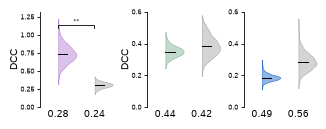

In [5]:
# use holm to find which p's are significant, use only those to report criticality
# POSSIBLE INTERPRET: ISA makes cortex closer to criticality !!!
fig, ax = fma.plotting.figure(n=(1,3),size=(8,3))
states = fit_cat.state.values
dcc = [[]] * 2
label = [[]] * 2
ylim = ((0,1.1), (0,0.5), (0,0.5))
for i, r in enumerate(regs):
    for j, s in enumerate(states):
        valid = np.all(~np.isnan(fit_cat.sel(reg=r,state=s,val='p')), axis=1) # sessions where a fit was performed
        h = fit_cat.sel(reg=r,state=s,val='p')[valid].values < 0.05
        signif = np.all(h, axis=1) # sessions where the fit was successful
        label[j] = f'{signif.mean():.2f}' # percentage of successful fits
        dcc[j] = exponents_cat.sel(reg=r,state=s,val='DCC')[valid]
        dcc[j][~signif] = np.nan
    valid = ~np.isnan(dcc[0]) | ~np.isnan(dcc[1]) # sessions where at least one condition was significant
    for j, s in enumerate(states):
        dcc[j] = dcc[j][valid]
        dcc[j][np.isnan(dcc[j])] = dcc[j][~np.isnan(dcc[j])].max() # input non significant fits with highest observed distance
    b = fma.statistics.hierarchicalBootstrap((dcc[0],dcc[1]), groups=(dcc[0].rat,dcc[1].rat))
    p = fma.statistics.hierarchicalBootstrapTest((dcc[0],dcc[1]), groups=(dcc[0].rat,dcc[1].rat), paired=True)
    print(p, end=' ')
    fma.plotting.boxPlot(b, mode='violin', color=isau.paperColors((r,'shuffle')), label=label, ax=ax[i])
    ax[i].set(xlim=(-0.5,1.5), ylim=ylim[i])
    fma.plotting.pBar([0,1,p], x=range(2), ax=ax[i])
ax[0].set(ylabel='DCC'); ax[1].set(ylabel='DCC')

do_save and fma.plotting.saveFigure(fig,fig_root / 'DCC_ISA_nISA',['png','svg'])

three brain states

In [6]:
fit, exponents, pdf, n_aval = fma.data.runBatch(batch_file,_critExp,kwargs={'regs':regs, 'states':['sws','rem','other'], 'bin_mode':'isi', 'bin':1, 'xmax':99.5},parallel=True)
fit_cat = xr.concat([f for f in fit if f is not None], dim='base', join='outer')
exponents_cat = xr.concat([f for f in exponents if f is not None], dim='base', join='outer')
results['fit_states'] = fit_cat; results['exp_states'] = exponents_cat; results['pdf_states'] = pdf


Starting Batch, 2026-11-03 16:55:18.943587 

Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230822/Rat002_20230822.xml (41)
/mnt/hubel-data-129/blinky/Rat002_20230822/Rat002_20230822.sws not found.
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230823/Rat002_20230823.xml (42)
/mnt/hubel-data-129/blinky/Rat002_20230823/Rat002_20230823.sws not found.
Traceback:
Error in session /mnt/hubel-data-149/Rat011/Rat011

/tmp/ipykernel_1675712/70068760.py:2: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  fit_cat = xr.concat([f for f in fit if f is not None], dim='base', join='outer')
/tmp/ipykernel_1675712/70068760.py:3: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  exponents_cat = xr.concat([f for f in exponents if f is not None]

[ 3  3  3  4  4  4  4  2  2 11 11 11 11 11 12 12 12 12]
[ 3  3  3  3  3  3  3  3  3  3  3  3  4  4  4  4  4  4  4  4  4  4 11 11
 11 11 12 12 12 12 12]
[ 3  3  3  3  3  3  3  3  3  3  4  4  4  4  4  4  4  4  4  4  4  4  4  2
  2  2  2  2  2 12 12 12]


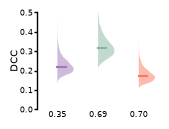

In [61]:
# use holm to find which p-s are signif, use only those to report criticality POSSIBLE INTERPRET: NR is the only to have many sessions crit in ISA! also, it is very non critical in wake
# MAYBE THIS COME BEFORE OTHER, DOES IT SURVIVE inter/spike interval BIN ?
fig, ax = fma.plotting.figure(size=(4,3))
dcc = []
label = []
p_val = []
boot = []
for i, r in enumerate(regs):
    valid = np.all(~np.isnan(fit_cat.sel(reg=r,state='sws',val='p')), axis=1) # sessions where a fit was performed
    h = fit_cat.sel(reg=r,state='sws',val='p')[valid].values < 0.05
    signif = np.all(h, axis=1) # sessions where the fit was successful
    label.append(f'{signif.mean():.2f}') # percentage of successful fits
    print(fit_cat.rat[valid][signif].values)
    dcc.append(exponents_cat.sel(reg=r,state='sws',val='DCC'))
    dcc[-1][~valid] = np.nan
    dcc[-1][valid][~signif] = np.nan

valid = ~np.isnan(dcc[0]) | ~np.isnan(dcc[1]) | ~np.isnan(dcc[2]) # sessions where at least one condition was significant
for j in range(len(dcc)):
    dcc[j] = dcc[j][valid]
    dcc[j][np.isnan(dcc[j])] = dcc[j][~np.isnan(dcc[j])].max() # input non significant fits with highest observed distance
    # bootstrap
    b, _ , _ = fma.statistics.hierarchicalBootstrap(dcc[j], dcc[j].rat, depth=2)
    boot.append(b)

#b, p , _ = fma.statistics.hierarchicalBootstrap(dcc[0], dcc[0].rat, dcc[1], dcc[1].rat, depth=2, paired=1)
#boot.extend([b[:,0,0],b[:,0,1]])
#p_val.append([2*i,2*i+1,p[0,-1]])
#fma.plotting.boxPlot(dcc, mode='scatter', color=isau.paperColors(regs))
fma.plotting.boxPlot(boot, mode='violin', color=isau.paperColors(regs), label=label)
#fma.plotting.pBar(p_val, x=range(len(regs) * 2))
ax[0].set(xlim=(-0.5,2.5), ylabel='DCC', ylim=(0,0.5))
do_save and fma.plotting.saveFigure(fig,fig_root / 'DCC_nREM',['png','svg'])

NR [ 3  3  3  4  4  4  4  2  2 11 11 11 11 11 12 12 12 12]
[ 3  3  2  2  2  2  2 11 11 12 12 12]
[ 3  3  3  3  3  3  3  3  3  3  3  3  3  3  4  4  4  4  4  4  4  4  4  4
  4  4  4  4  4  4  4  2  2  2  2  2  2 11 11 11 11 12 12 12 12 12 12 12]
HPC [ 3  3  3  3  3  3  3  3  3  3  3  3  4  4  4  4  4  4  4  4  4  4 11 11
 11 11 12 12 12 12 12]
[ 3  3  3  4  4 12]
[ 3  3  3  3  3  3  3  3  3  3  3  4  4  4  4  4  4  4 11 11 12 12 12 12
 12 12]
PFC [ 3  3  3  3  3  3  3  3  3  3  4  4  4  4  4  4  4  4  4  4  4  4  4  2
  2  2  2  2  2 12 12 12]
[ 3  3  3  3  4  4  4  2  2  2  2 12]
[ 3  3  3  3  3  3  3  3  3  3  3  3  4  4  4  4  4  4  4  4  4  4  4  4
  4  4  4  4  4  2  2  2  2 12 12]


False

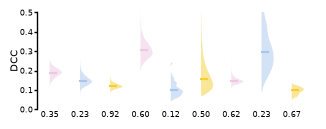

In [9]:
# use holm to find which p-s are signif, use only those to report criticality POSSIBLE INTERPRET: NR is the only to have many sessions crit in ISA! also, it is very non critical in wake
# MAYBE THIS COME BEFORE OTHER
fig, ax = fma.plotting.figure(size=(8,3))
states = fit_cat.state.values
dcc = []
label = []
p_val = []
boot = []
for i, r in enumerate(regs):
    print(r.upper(),end=' ')
    for j, s in enumerate(states):
        #_, h = fma.analysis.holmBonferroni(fit_cat.sel(reg=r,state=s,val='p'),return_reject=True)
        h = fit_cat.sel(reg=r,state=s,val='p').values < 0.05
        label.append(f'{np.all(h,axis=1).mean():.2f}')
        print(fit_cat.rat[np.all(h,axis=1)].values)
        dcc.append(exponents_cat.sel(reg=r,state=s,val='DCC')[np.all(h,axis=1)])
        b, _ , _ = fma.statistics.hierarchicalBootstrap(dcc[-1], dcc[-1].rat, depth=2)
        boot.append(b)
    #b, p , _ = fma.statistics.hierarchicalBootstrap(dcc[0], dcc[0].rat, dcc[1], dcc[1].rat, depth=2, paired=1)
    #boot.extend([b[:,0,0],b[:,0,1]])
    #p_val.append([2*i,2*i+1,p[0,-1]])
fma.plotting.boxPlot(boot, mode='violin', color=isau.paperColors(np.tile(fit_cat.state.values,3).ravel('F')), label=label)
#fma.plotting.pBar(p_val, x=range(len(regs) * 2))
ax[0].set(ylabel='DCC', ylim=(0,0.5))
do_save and fma.plotting.saveFigure(fig,fig_root / 'DCC_states',['png','svg'])

sleep 2


Starting Batch, 2026-11-03 17:33:07.934529 

Error in session /mnt/hubel-data-139/karadoc/Rat004_20240303/Rat004_20240303.xml (17)
index 0 is out of bounds for axis 0 with size 0
Traceback:
Error in session /mnt/hubel-data-140/karadoc/Rat004_20240313/Rat004_20240313.xml (24)
index 0 is out of bounds for axis 0 with size 0
Traceback:
Error in session /mnt/hubel-data-140/karadoc/Rat004_20240318/Rat004_20240318.xml (29)
index 0 is out of bounds for axis 0 with size 0
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_202308

/tmp/ipykernel_1675712/881502438.py:3: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  fit_cat = xr.concat([f for f in fit if f is not None], dim='base', join='outer')
/tmp/ipykernel_1675712/881502438.py:4: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  exponents_cat = xr.concat([f for f in exponents if f is not Non

0.894 

[Text(0, 0.5, 'DCC')]

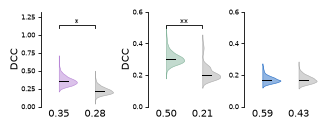

In [10]:
regs = ['nr','hpc','pfc']
fit, exponents, pdf, n_aval = fma.data.runBatch(batch_file, _critExp, kwargs={'when':'sleep.*#1', 'regs':regs, 'bin_mode':'isi', 'bin':1, 'xmax':99.5}, parallel=True)
fit_cat = xr.concat([f for f in fit if f is not None], dim='base', join='outer')
exponents_cat = xr.concat([f for f in exponents if f is not None], dim='base', join='outer')
results['fit_ISA_s2'] = fit_cat; results['exp_ISA_s2'] = exponents_cat; results['pdf_ISA_s2'] = pdf

fig, ax = fma.plotting.figure(n=(1,3),size=(8,3))
states = fit_cat.state.values
dcc = [[]] * 2
label = [[]] * 2
ylim = ((0,1.1), (0,0.5), (0,0.5))
for i, r in enumerate(regs):
    for j, s in enumerate(states):
        valid = np.all(~np.isnan(fit_cat.sel(reg=r,state=s,val='p')), axis=1) # sessions where a fit was performed
        h = fit_cat.sel(reg=r,state=s,val='p')[valid].values < 0.05
        signif = np.all(h, axis=1) # sessions where the fit was successful
        label[j] = f'{signif.mean():.2f}' # percentage of successful fits
        dcc[j] = exponents_cat.sel(reg=r,state=s,val='DCC')#[valid]
        dcc[j][~valid] = np.nan
        dcc[j][valid][~signif] = np.nan
        #dcc[j][~signif] = np.nan
    valid = ~np.isnan(dcc[0]) | ~np.isnan(dcc[1]) # sessions where at least one condition was significant
    for j, s in enumerate(states):
        dcc[j] = dcc[j][valid]
        dcc[j][np.isnan(dcc[j])] = dcc[j][~np.isnan(dcc[j])].max() # input non significant fits with highest observed distance
    b = fma.statistics.hierarchicalBootstrap((dcc[0],dcc[1]), groups=(dcc[0].rat,dcc[1].rat))
    p = fma.statistics.hierarchicalBootstrapTest((dcc[0],dcc[1]), groups=(dcc[0].rat,dcc[1].rat), paired=True)
    print(p, end=' ')
    fma.plotting.boxPlot(b, mode='violin', color=isau.paperColors((r,'shuffle')), label=label, ax=ax[i])
    ax[i].set(xlim=(-0.5,1.5), ylim=ylim[i])
    fma.plotting.pBar([0,1,p], x=range(2), ax=ax[i])
ax[0].set(ylabel='DCC'); ax[1].set(ylabel='DCC')

In [8]:
fit, exponents, pdf, n_aval = fma.data.runBatch(batch_file,_critExp,kwargs={'when':'sleep.*#1', 'regs':regs, 'states':['sws','rem','other'], 'bin_mode':'isi', 'bin':1, 'xmax':99.5},parallel=True)
fit_cat = xr.concat([f for f in fit if f is not None], dim='base', join='outer')
exponents_cat = xr.concat([f for f in exponents if f is not None], dim='base', join='outer')
results['fit_states_s2'] = fit_cat; results['exp_states_s2'] = exponents_cat; results['pdf_states_s2'] = pdf


Starting Batch, 2026-11-03 16:55:56.512784 

Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230822/Rat002_20230822.xml (41)
/mnt/hubel-data-129/blinky/Rat002_20230822/Rat002_20230822.sws not found.
Traceback:
Error in session /mnt/hubel-data-129/blinky/Rat002_20230823/Rat002_20230823.xml (42)
/mnt/hubel-data-129/blinky/Rat002_20230823/Rat002_20230823.sws not found.
Traceback:
Error in session /mnt/hubel-data-149/Rat011/Rat011

/tmp/ipykernel_1675712/3549385498.py:2: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  fit_cat = xr.concat([f for f in fit if f is not None], dim='base', join='outer')
/tmp/ipykernel_1675712/3549385498.py:3: FutureWarning: In a future version of xarray the default value for coords will change from coords='different' to coords='minimal'. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set coords explicitly.
  exponents_cat = xr.concat([f for f in exponents if f is not N

Coupled vs uncoupled ripples

In [7]:
regs = ['nr','hpc','pfc']
fit, exponents, pdf, n_aval = fma.data.runBatch(batch_file, _critExp, kwargs={'regs':regs, 'states':'rip_coupl', 'bin_mode':'isi', 'bin':1, 'xmax':99.5}, parallel=True)
fit_cat = xr.concat([f for f in fit if f is not None], dim='rat', join='outer')
exponents_cat = xr.concat([f for f in exponents if f is not None], dim='rat', join='outer')
n = xr.concat([f for f in n_aval if f is not None], dim='rat', join='outer')


Starting Batch, 2026-11-02 14:56:53.196446 

Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.xml (31)
/mnt/hubel-data-148/blinky/Training/Rat002_20230807/Rat002_20230807.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.xml (32)
/mnt/hubel-data-148/blinky/Training/Rat002_20230808/Rat002_20230808.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.xml (33)
/mnt/hubel-data-148/blinky/Training/Rat002_20230810/Rat002_20230810.sws not found.
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230815/Rat002_20230815.xml (34)
only integer scalar arrays can be converted to a scalar index
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat002_20230816/Rat002_20230816.xml (35)
only integer scalar arrays can be converted to a scalar index
Traceback:
Error in session /mnt/hubel-data-148/blinky/Training/Rat

In [ ]:
results['fit_coupl'] = fit_cat; results['exp_coupl'] = exponents_cat; results['pdf_coupl'] = pdf

[False False False False  True False False False False False False False
 False  True False False  True False False False False False False False
 False False False False False False False False False False False False
 False False]
[False  True False False False False False False False  True False False
 False False False False False False False False False False False False
 False False False False False False False False False  True  True  True
 False  True]
0.318 [False  True False False False False False False False  True  True False
 False False False  True False False False False False False False False
 False False False False  True False False False False False False False
 False False]
[False False False  True  True False  True False  True  True False False
  True  True False False False False  True False  True  True False  True
 False  True False False  True  True  True  True  True  True  True False
  True  True]
0.862 [False False False  True False False False False False F

/home/pietro/uvEnvs/fmat/lib/python3.14/site-packages/hierarch/stats.py:536: UserWarning: No levels to bootstrap. Setting bootstraps to zero.
  warn("No levels to bootstrap. Setting bootstraps to zero.")
/home/pietro/uvEnvs/fmat/lib/python3.14/site-packages/hierarch/stats.py:536: UserWarning: No levels to bootstrap. Setting bootstraps to zero.
  warn("No levels to bootstrap. Setting bootstraps to zero.")
/home/pietro/uvEnvs/fmat/lib/python3.14/site-packages/hierarch/stats.py:536: UserWarning: No levels to bootstrap. Setting bootstraps to zero.
  warn("No levels to bootstrap. Setting bootstraps to zero.")


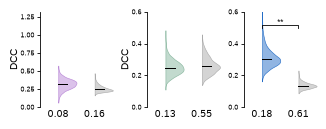

In [8]:
fig, ax = fma.plotting.figure(n=(1,3),size=(8,3))
states = fit_cat.state.values
ylim = ((0,1.1), (0,0.5), (0,0.5))
label = [[]] * 2
for i, r in enumerate(regs):
    dcc = []
    for j, s in enumerate(states):
        valid = np.all(~np.isnan(fit_cat.sel(reg=r,state=s,val='p')), axis=1) # sessions where a fit was performed
        h = fit_cat.sel(reg=r,state=s,val='p')[valid].values < 0.05
        signif = np.all(h, axis=1) # sessions where the fit was successful
        print(signif)
        label[j] = f'{signif.mean():.2f}' # percentage of successful fits
        dcc.append(exponents_cat.sel(reg=r,state=s,val='DCC'))
        dcc[-1][~valid] = np.nan
        dcc[-1][valid][~signif] = np.nan
    valid = ~np.isnan(dcc[0]) | ~np.isnan(dcc[1]) # sessions where at least one condition was significant
    for j, s in enumerate(states):
        dcc[j] = dcc[j][valid]
        dcc[j][np.isnan(dcc[j])] = dcc[j][~np.isnan(dcc[j])].max() # input non significant fits with highest observed distance
    b = fma.statistics.hierarchicalBootstrap((dcc[0],dcc[1]), groups=(dcc[0].rat,dcc[1].rat))
    p = fma.statistics.hierarchicalBootstrapTest((dcc[0],dcc[1]), groups=(dcc[0].rat,dcc[1].rat), paired=True)
    print(p, end=' ')
    fma.plotting.boxPlot(b, mode='violin', color=isau.paperColors((r,'shuffle')), label=label, ax=ax[i])
    ax[i].set(xlim=(-0.5,1.5), ylim=ylim[i])
    fma.plotting.pBar([0,1,p], x=range(2), ax=ax[i])
ax[0].set(ylabel='DCC'); ax[1].set(ylabel='DCC');

In [ ]:
do_save and isau.update_results(results, fres)